<a href="https://colab.research.google.com/github/difanaya/PCVK_Ganjil_2026/blob/main/Modul6/Modul6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 6 - Filter Spasial: Low Pass, High Pass, Point/Line/Edge Detection

**Nama :** Difa Naya Sari Pasha

**NIM :** 244107020213


## Setup

In [2]:
NAMA = 'Difa Naya Sari Pasha'
NIM  = '244107020213'

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math
from google.colab.patches import cv2_imshow

In [3]:
from google.colab import drive
drive.mount('/content/drive')

CONTOH = '/content/drive/MyDrive/PCVK/Images'            # citra contoh bersama
BASE   = '/content/drive/MyDrive/PCVK/Images/' + NIM     # citra milik Anda
print('CONTOH :', CONTOH)
print('BASE   :', BASE)

CONTOH : /content/drive/MyDrive/PCVK/Images
BASE   : /content/drive/MyDrive/PCVK/Images/244107020213


## Fungsi Bantu

In [4]:
def show_side_by_side(images, titles, figsize=(16, 4)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(1, n, i)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## D. Praktikum Filter

### 1. Fungsi konvolusi manual

Mengikuti pseudocode pada modul: untuk setiap piksel citra, jumlahkan hasil kali kernel dengan
piksel tetangganya. Tanpa memakai fungsi konvolusi dari OpenCV.

In [5]:
def konvolusi(image, kernel, padding='zero'):
    img = image.astype(np.float32)
    if img.ndim == 3:                                   # paksa keabuan bila berwarna
        img = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32)

    H, W   = img.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    if padding == 'zero':
        pad = np.zeros((H + 2 * ph, W + 2 * pw), np.float32)
        pad[ph:ph + H, pw:pw + W] = img
    elif padding == 'replicate':
        pad = np.pad(img, ((ph, ph), (pw, pw)), mode='edge')
    else:
        pad = np.pad(img, ((ph, ph), (pw, pw)), mode='constant')

    out = np.zeros((H, W), np.float32)
    for y in range(H):
        for x in range(W):
            region = pad[y:y + kh, x:x + kw]
            out[y, x] = np.sum(region * kernel)         # penjumlahan hasil kali
    return np.clip(out, 0, 255).astype(np.uint8)

### 2. Load citra dan ubah ke keabuan

In [6]:
img  = cv.imread(CONTOH + '/lena.jpg')
gray = cv.imread(CONTOH + '/lena.jpg', cv.IMREAD_GRAYSCALE)
print('ukuran citra :', gray.shape)

ukuran citra : (512, 512)


### 3. Kernel penajaman (sharpening) dan pemanggilan fungsi konvolusi

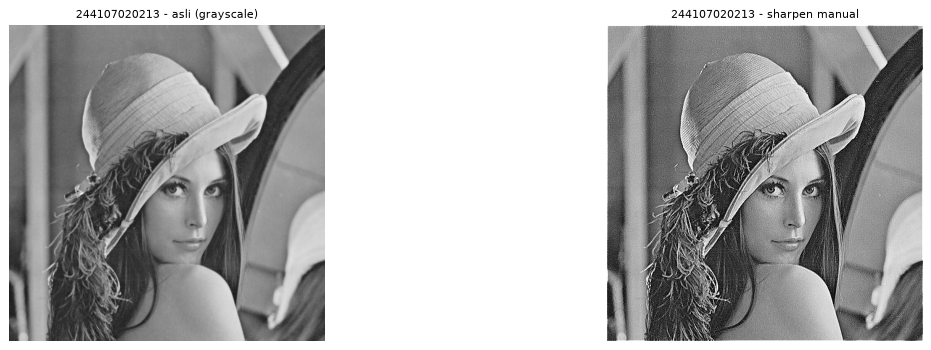

In [7]:
kernel_sharpen = np.array([[0, -1, 0],
                         [-1, 5, -1],
                         [0, -1, 0]], np.float32)

hasil_sharpen = konvolusi(gray, kernel_sharpen)
show_side_by_side([gray, hasil_sharpen], ['asli (grayscale)', 'sharpen manual'])

### 4. Berbagai filter dengan kernel

Average, low pass, high pass, sharpen, emboss, Sobel, dan Gaussian 21x21.

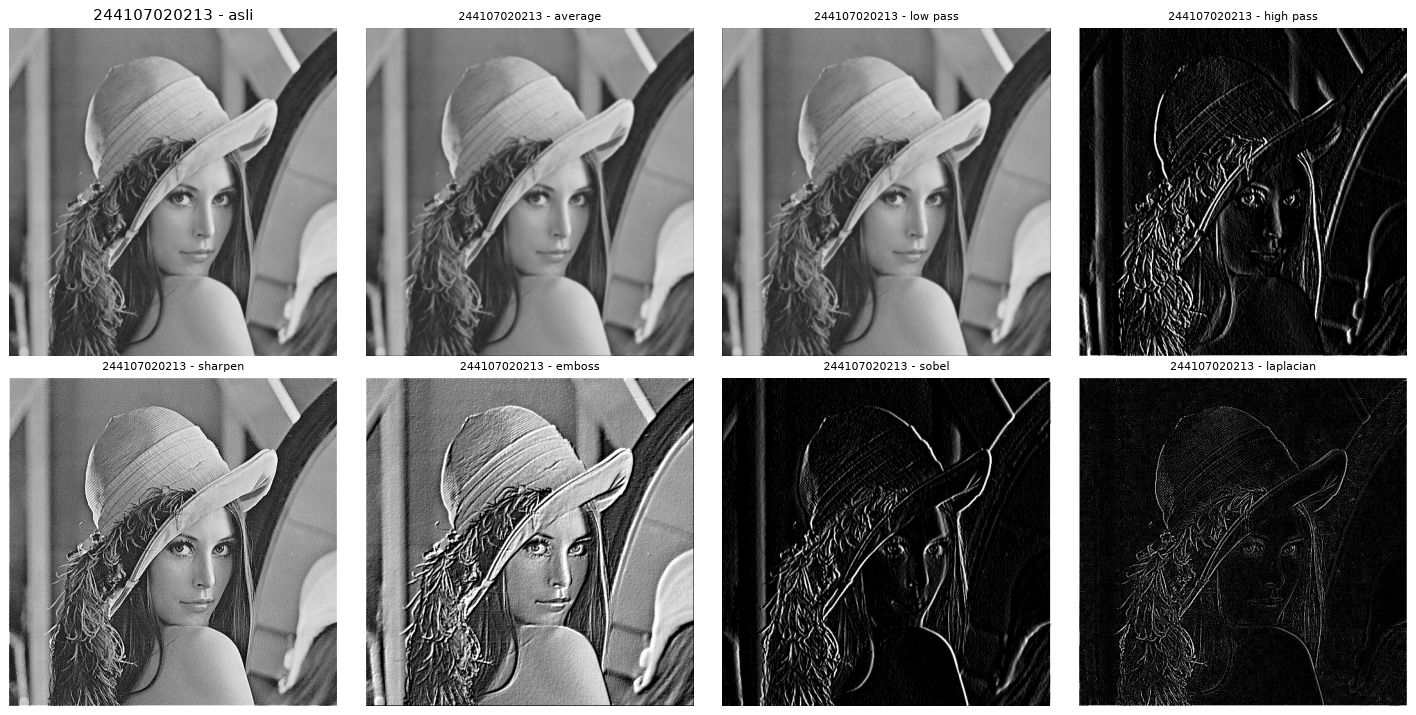

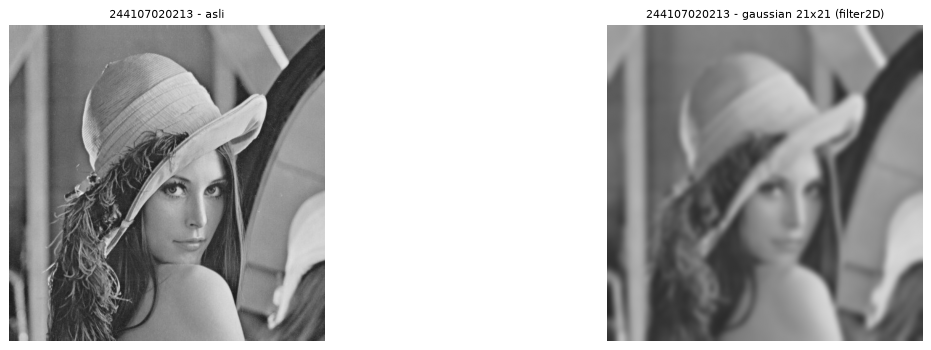

In [8]:
kernel_average  = np.ones((3, 3), np.float32) / 9
kernel_lowpass  = np.array([[1, 1, 1],
                            [1, 4, 1],
                            [1, 1, 1]], np.float32) / 12
kernel_highpass = np.array([[-1, 0, 1],
                            [-1, 0, 3],
                            [-3, 0, 1]], np.float32)
kernel_emboss   = np.array([[-2, -1, 0],
                            [-1, 1, 1],
                            [0, 1, 2]], np.float32)
kernel_sobel    = np.array([[1, 0, -1],
                            [2, 0, -2],
                            [1, 0, -1]], np.float32)
kernel_laplace  = np.array([[-1, -1, -1],
                            [-1, 8, -1],
                            [-1, -1, -1]], np.float32)

# Gaussian 21x21
sigma = math.sqrt(21)
g = cv.getGaussianKernel(21, sigma)
kernel_gauss = (g @ g.T).astype(np.float32)

daftar = [('average', kernel_average), ('low pass', kernel_lowpass),
          ('high pass', kernel_highpass), ('sharpen', kernel_sharpen),
          ('emboss', kernel_emboss), ('sobel', kernel_sobel),
          ('laplacian', kernel_laplace)]

plt.figure(figsize=(16, 8))
plt.subplot(2, 4, 1)
plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - asli')
plt.axis('off')
for i, (nama, k) in enumerate(daftar):
    plt.subplot(2, 4, i + 2)
    plt.imshow(konvolusi(gray, k), cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + nama, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

# kernel 21x21 dikonvolusi memakai cv.filter2D karena perulangan manual 21x21 terlalu lambat
gauss21 = cv.filter2D(gray, -1, kernel_gauss)
show_side_by_side([gray, gauss21], ['asli', 'gaussian 21x21 (filter2D)'])

### 5. Library filter: `filter2D` pada citra RGB

Filter Gaussian, Sharpen, dan Canny (versi library OpenCV).

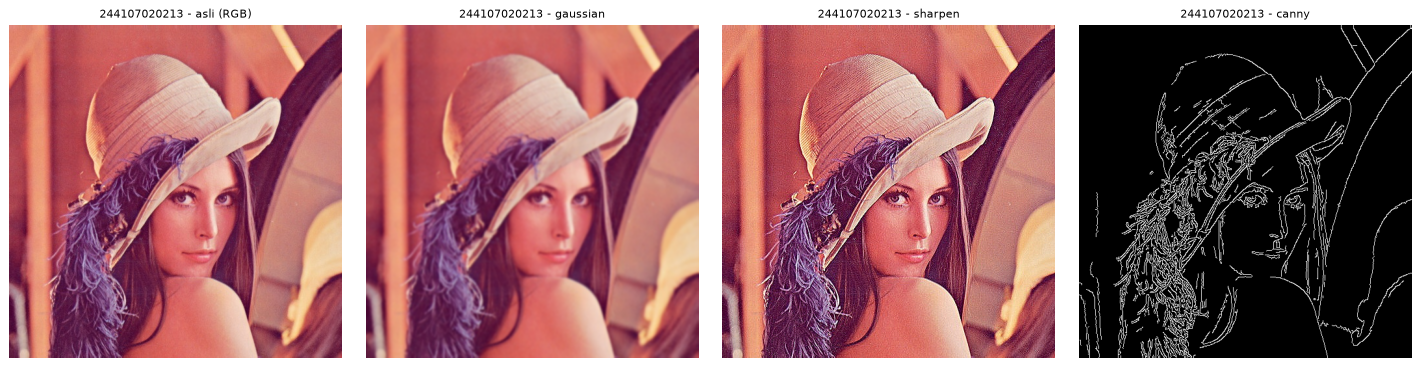

In [9]:
rgb = cv.imread(CONTOH + '/lena.jpg')

gaussian = cv.GaussianBlur(rgb, (7, 7), 0)
sharp    = cv.filter2D(rgb, -1, kernel_sharpen)
canny    = cv.Canny(rgb, 100, 200)

show_side_by_side([rgb, gaussian, sharp, canny],
                  ['asli (RGB)', 'gaussian', 'sharpen', 'canny'])

### 6. Filter modern: Bilateral dan Guided

Bilateral filtering menghaluskan citra namun mempertahankan tepi. Guided filter bekerja lebih cepat
dengan asumsi hasil adalah fungsi linear dari citra pemandu (di sini pemandunya citra itu sendiri).

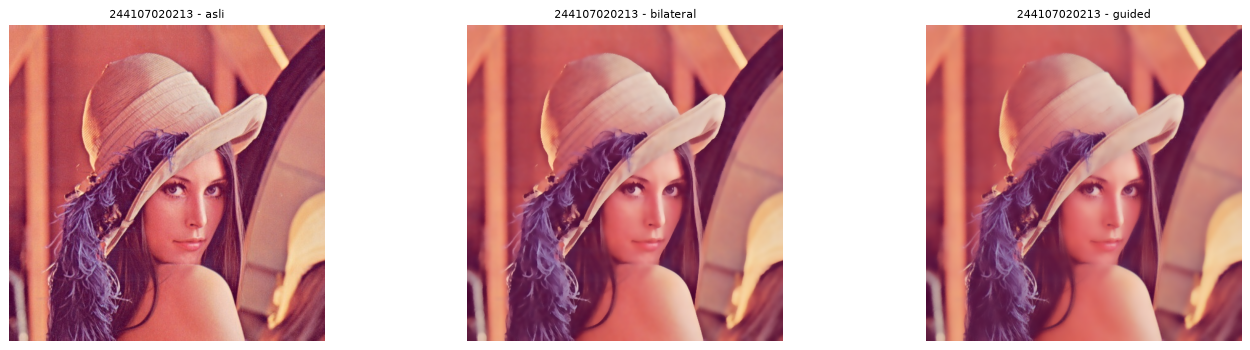

In [10]:
def guided_filter(I, p, r, eps):
    mean_I  = cv.boxFilter(I, cv.CV_32F, (r, r))
    mean_p  = cv.boxFilter(p, cv.CV_32F, (r, r))
    mean_Ip = cv.boxFilter(I * p, cv.CV_32F, (r, r))
    cov_Ip  = mean_Ip - mean_I * mean_p
    mean_II = cv.boxFilter(I * I, cv.CV_32F, (r, r))
    var_I   = mean_II - mean_I * mean_I
    a = cov_Ip / (var_I + eps)
    b = mean_p - a * mean_I
    mean_a = cv.boxFilter(a, cv.CV_32F, (r, r))
    mean_b = cv.boxFilter(b, cv.CV_32F, (r, r))
    return mean_a * I + mean_b


def guided_warna(bgr, r=8, eps=0.01):
    f   = bgr.astype(np.float32) / 255.0
    out = np.zeros_like(f)
    for i in range(3):
        out[:, :, i] = guided_filter(f[:, :, i], f[:, :, i], r, eps)
    return np.clip(out * 255, 0, 255).astype(np.uint8)


bilateral = cv.bilateralFilter(rgb, 9, 75, 75)
guided    = guided_warna(rgb, r=8, eps=0.01)
show_side_by_side([rgb, bilateral, guided], ['asli', 'bilateral', 'guided'])

### 7. Filtering pada CNN (feature map)

Setiap kernel acak bertindak seperti satu filter pada layer konvolusi dan menghasilkan satu feature
map. Jalankan beberapa kali dan perhatikan keluaran yang selalu berubah.

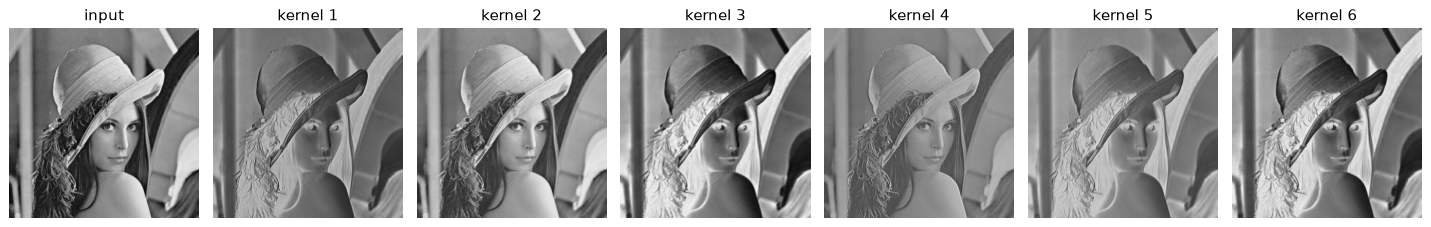

In [11]:
def feature_map(img, n=6, ksize=3):
    g = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    plt.figure(figsize=(16, 3))
    plt.subplot(1, n + 1, 1)
    plt.imshow(g, cmap='gray')
    plt.title('input')
    plt.axis('off')
    for i in range(n):
        k = np.random.randn(ksize, ksize).astype(np.float32)
        f = cv.filter2D(g, -1, k)
        plt.subplot(1, n + 1, i + 2)
        plt.imshow(f, cmap='gray')
        plt.title('kernel %d' % (i + 1))
        plt.axis('off')
    plt.tight_layout()
    plt.show()


feature_map(rgb)

Kesimpulan: tiap kernel ngasilin feature map beda karena tiap kernel nyorot pola tertentu (tepi,
arah, tekstur). Karena bobotnya masih acak dan belum dilatih, hasilnya berubah tiap kali dijalankan
dan belum bermakna. Di CNN, bobot inilah yang dilatih dari data biar feature map-nya berguna.

### 8. Filter efek: Beauty dan Vintage

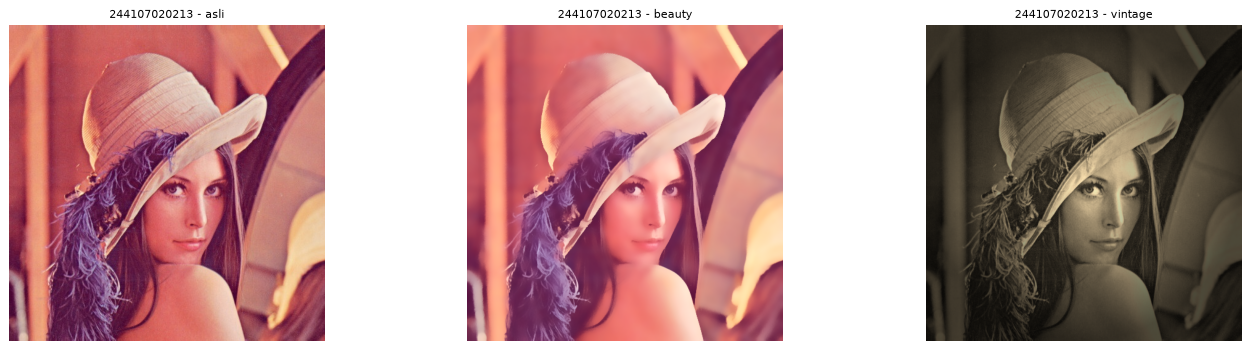

In [12]:
def beauty(img):
    halus  = cv.bilateralFilter(img, 15, 80, 80)     # melembutkan tekstur, tepi tetap
    cerah  = cv.convertScaleAbs(halus, alpha=1.05, beta=10)
    return cerah


def vintage(img):
    m = np.array([[0.272, 0.534, 0.131],             # matriks sepia (BGR)
                  [0.349, 0.686, 0.168],
                  [0.393, 0.769, 0.189]])
    sepia = np.clip(cv.transform(img, m), 0, 255).astype(np.uint8)
    h, w  = img.shape[:2]
    X, Y  = np.meshgrid(np.arange(w), np.arange(h))
    d     = np.sqrt((X - w / 2) ** 2 + (Y - h / 2) ** 2)
    mask  = np.clip(1 - d / d.max(), 0.3, 1)         # vignette
    return (sepia * mask[:, :, None]).astype(np.uint8)


show_side_by_side([rgb, beauty(rgb), vintage(rgb)], ['asli', 'beauty', 'vintage'])

### 9. Filter Kartun (kombinasi filter tradisional)

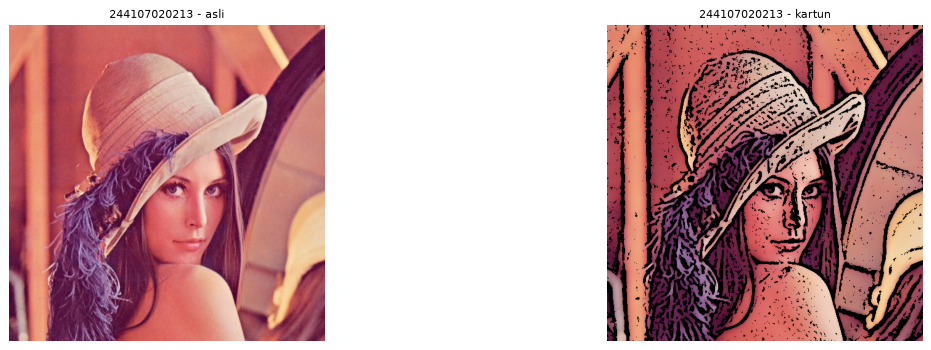

In [13]:
def kartun(img):
    warna = cv.bilateralFilter(img, 9, 75, 75)
    warna = cv.bilateralFilter(warna, 9, 75, 75)     # penghalusan warna
    abu   = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    abu   = cv.medianBlur(abu, 5)
    tepi  = cv.adaptiveThreshold(abu, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 2)
    tepi  = cv.cvtColor(tepi, cv.COLOR_GRAY2BGR)
    return cv.bitwise_and(warna, tepi)               # gabung warna rata + garis tepi


show_side_by_side([rgb, kartun(rgb)], ['asli', 'kartun'])

### 10. Filter Malam

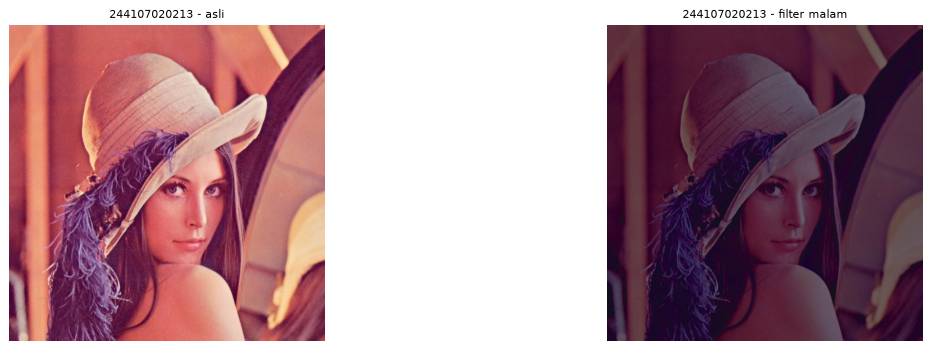

In [14]:
def filter_malam(img):
    gelap = cv.convertScaleAbs(img, alpha=0.5, beta=-20)   # turunkan kecerahan
    b, g, r = cv.split(gelap)
    b = cv.add(b, 25)                                       # tint kebiruan
    return cv.merge([b, g, r])


show_side_by_side([rgb, filter_malam(rgb)], ['asli', 'filter malam'])

### 11. Filter Pagi dan Pagi + Kabut

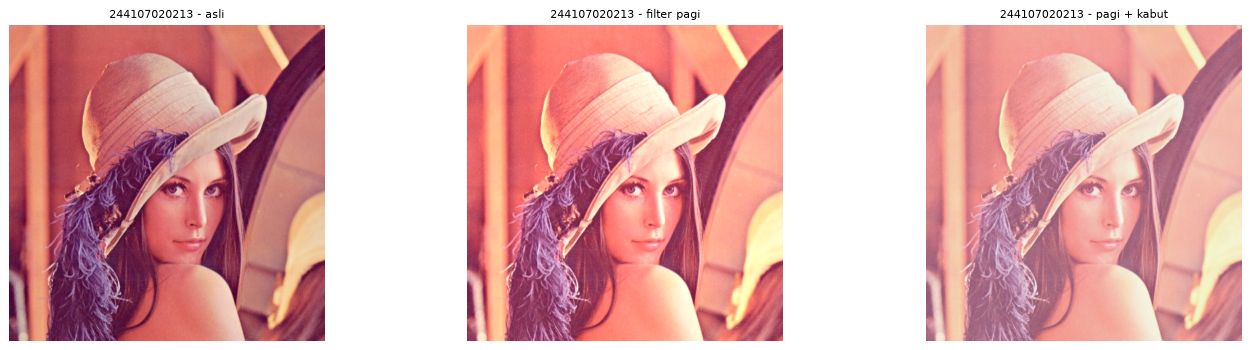

In [15]:
def filter_pagi(img):
    hangat = cv.convertScaleAbs(img, alpha=1.1, beta=25)
    b, g, r = cv.split(hangat)
    r = cv.add(r, 15)                                       # tint hangat
    b = cv.subtract(b, 10)
    return cv.merge([b, g, r])


def tambah_kabut(img):
    return cv.addWeighted(img, 0.7, np.full_like(img, 220), 0.3, 0)


show_side_by_side([rgb, filter_pagi(rgb), tambah_kabut(filter_pagi(rgb))],
                  ['asli', 'filter pagi', 'pagi + kabut'])

## Tugas Praktikum

### Tugas 1 - Mean Filter vs Median Filter pada noise Salt and Pepper

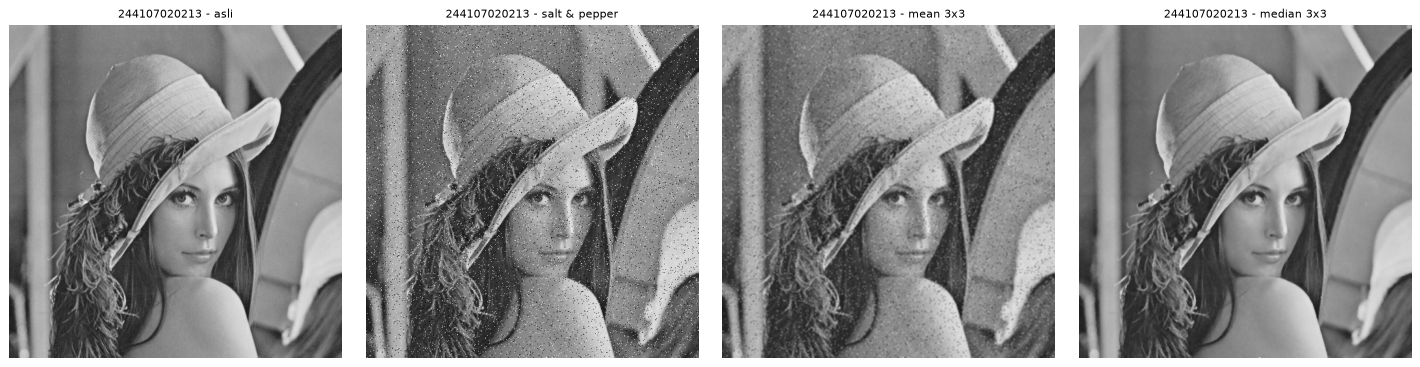

In [16]:
def salt_pepper(img, amount=0.05):
    out = img.copy()
    n   = int(amount * img.size)
    ys  = np.random.randint(0, img.shape[0], n)
    xs  = np.random.randint(0, img.shape[1], n)
    half = n // 2
    out[ys[:half], xs[:half]] = 0        # pepper (hitam)
    out[ys[half:], xs[half:]] = 255      # salt (putih)
    return out


abu_noise = salt_pepper(gray, 0.05)

mean_f   = cv.blur(abu_noise, (3, 3))
median_f = cv.medianBlur(abu_noise, 3)

show_side_by_side([gray, abu_noise, mean_f, median_f],
                  ['asli', 'salt & pepper', 'mean 3x3', 'median 3x3'])

Median filter jauh lebih bersih. Noise salt and pepper itu impuls: nilainya ekstrem (0 atau 255)
dan nggak nyambung sama tetangganya. Mean filter ngerata-ratain semua tetangga jadi nilai ekstremnya
ikut nyebar dan nyisa noda kabur. Median ambil nilai tengah, karena noise cuma sebagian kecil dari
jendela, nilai tengahnya tetap dari piksel normal jadi noise kebuang tanpa nguberin tepi.

### Tugas 2 - Pemilihan ukuran kernel terbaik untuk sharpening

blur          : var laplacian     32.1 , std   5.66
sharpen 3x3   : var laplacian    218.3 , std  14.77
sharpen 5x5   : var laplacian   7350.0 , std  85.73


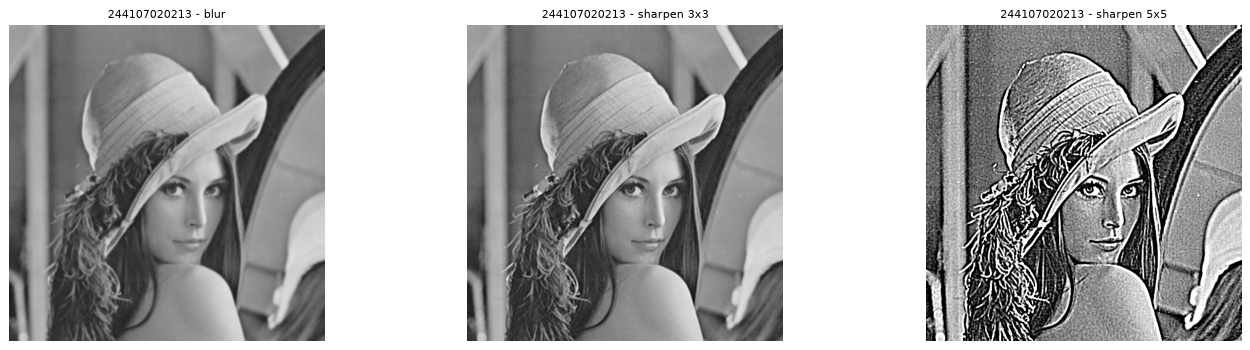

In [17]:
k3 = np.array([[0, -1, 0],
               [-1, 5, -1],
               [0, -1, 0]], np.float32)

k5 = np.array([[-1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1],
               [-1, -1, 25, -1, -1],
               [-1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1]], np.float32)

blur = cv.GaussianBlur(gray, (5, 5), 0)        # citra sedikit buram
s3 = cv.filter2D(blur, -1, k3)
s5 = cv.filter2D(blur, -1, k5)

def ukur(img):
    lap = cv.Laplacian(img, cv.CV_64F).var()   # kejelasan tepi
    noise = cv.Laplacian(img, cv.CV_64F).std()  # kadar noise
    return lap, noise

for nama, im in [('blur', blur), ('sharpen 3x3', s3), ('sharpen 5x5', s5)]:
    lap, noise = ukur(im)
    print('%-13s : var laplacian %8.1f , std %6.2f' % (nama, lap, noise))

show_side_by_side([blur, s3, s5], ['blur', 'sharpen 3x3', 'sharpen 5x5'])

Kernel 3x3 udah cukup buat najemin tepi dengan noise yang masih aman, jadi paling oke buat
pemakaian sehari-hari. Kernel 5x5 lebih agresif (var Laplacian jauh lebih tinggi) tapi ikut nguatin
noise dan muncul halo di sekitar tepi, jadi cuma cocok kalau citranya bersih.

### Tugas 3 - Filter kartun sederhana `kartun(image)`

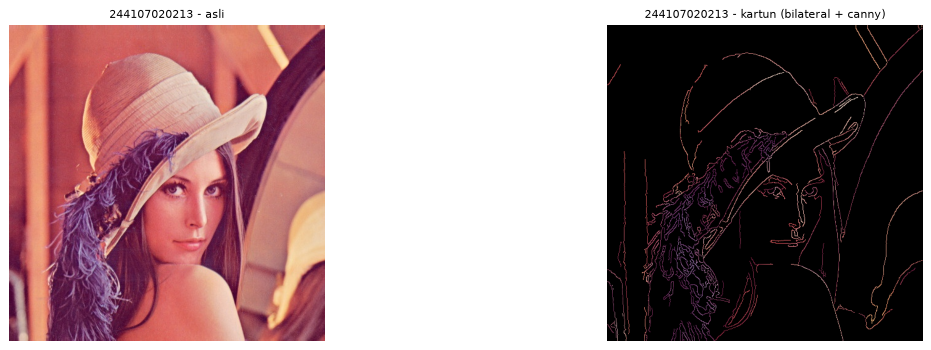

In [18]:
def kartun(image):
    # 1. penghalusan warna dengan Bilateral Filter
    warna = cv.bilateralFilter(image, 9, 75, 75)
    warna = cv.bilateralFilter(warna, 9, 75, 75)

    # 2. deteksi garis tepi dengan Canny Edge
    abu  = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    abu  = cv.medianBlur(abu, 5)
    tepi = cv.Canny(abu, 50, 150)
    tepi = cv.cvtColor(tepi, cv.COLOR_GRAY2BGR)

    # 3. gabungkan dengan operasi perkalian piksel
    return cv.bitwise_and(warna, tepi)


hasil = kartun(rgb)
show_side_by_side([rgb, hasil], ['asli', 'kartun (bilateral + canny)'])

---
**Selamat Belajar**